# 09 · Recalled causes and years of drying
Among dried sources: reported causes and years; Knox space–time test within vs across wards; ward ICC of causes and
years against matched grids; apriori narrative rules with ward-stratified tests
(`src/descriptive.py`, `src/spatial_analysis.py`, `src/unsupervised.py`, `src/pattern_mining.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
display(table("drying_reasons.csv")); table("drying_timing_summary.csv")

,reported_reason,n_dried,share
0,earthquake,521,0.3425
1,drought,477,0.3136
2,infrastructure_development,240,0.1578
3,natural_disaster,113,0.0743
4,source_neglected,96,0.0631
5,source_disruption,46,0.0302
6,deforestation,16,0.0105
7,reduced precipitation,8,0.0053
8,wa reason,3,0.0020
9,pine plantation,1,0.0007


,n_dried,n_valid_year,n_dried_in_2072BS,share_dried_in_2072BS,share_earthquake_attributed_among_2072BS,n_earthquake_attributed,share_of_earthquake_attributed_in_2072BS,share_dried_before_2072BS,share_dried_after_2072BS
0,1521,1513,538,0.3537,0.8401,521,0.8676,0.4057,0.2354


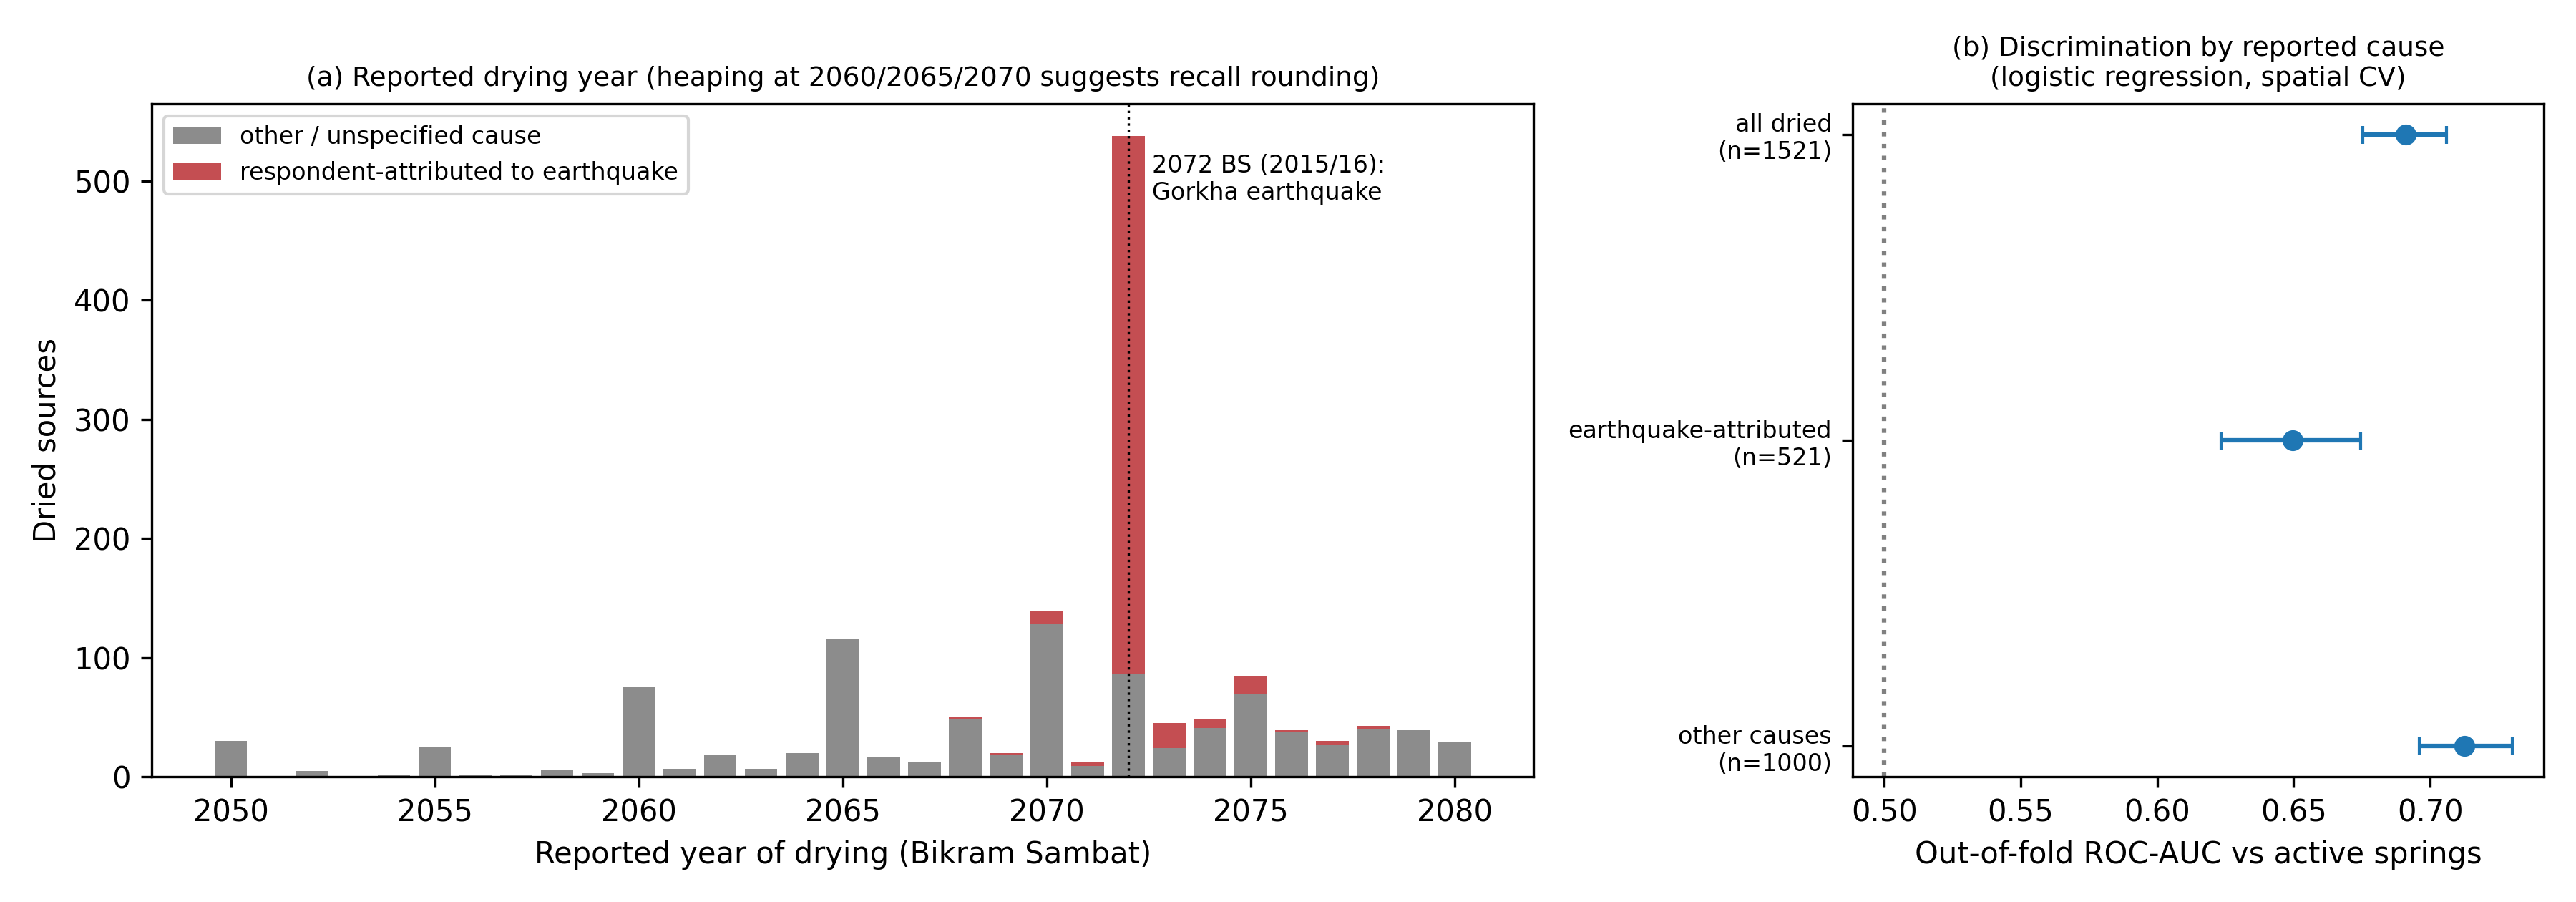

In [3]:
fig("drying_timing_and_cause.png")

## Knox test: same reported year, within vs across wards

In [4]:
k = table("sa_knox_test.csv"); k[k.time_years == 0]

,cohort,pairs,n_sources,space_m,time_years,n_close_pairs,observed,expected,ratio_obs_exp,p_value
0,all dried with valid year,all pairs,1513,250,0,2242,529,342.8358,1.5430,0.001
2,all dried with valid year,same ward,1513,250,0,2046,507,315.5546,1.6067,0.001
4,all dried with valid year,different ward,1513,250,0,196,22,29.9479,0.7346,0.824
6,all dried with valid year,all pairs,1513,500,0,5597,1219,856.3133,1.4235,0.001
8,all dried with valid year,same ward,1513,500,0,4630,1111,707.5536,1.5702,0.001
10,all dried with valid year,different ward,1513,500,0,967,108,148.7137,0.7262,0.948
12,all dried with valid year,all pairs,1513,1000,0,13904,2701,2135.9359,1.2646,0.001
14,all dried with valid year,same ward,1513,1000,0,10168,2309,1561.3113,1.4789,0.001
16,all dried with valid year,different ward,1513,1000,0,3736,392,572.5455,0.6847,1.000
18,excluding 2072 BS cohort,all pairs,975,250,0,1512,219,98.8579,2.2153,0.001


## Ward ICC of recalled attributes vs matched grids and landscape types

,outcome,share,unit,n_units,icc,grid_icc_mean,grid_icc_q025,grid_icc_q975,p_above_grid,cramers_v
0,earthquake attributed,0.3425,ward,75,0.2283,0.1518,0.1308,0.1767,0.005,0.4624
1,earthquake attributed,0.3425,landscape type,8,0.0495,NaN,NaN,NaN,NaN,0.1996
2,drought attributed,0.3136,ward,75,0.2515,0.1870,0.1549,0.2240,0.005,0.4854
3,drought attributed,0.3136,landscape type,8,0.0387,NaN,NaN,NaN,NaN,0.1761
4,infrastructure attributed,0.1578,ward,75,0.2642,0.1801,0.1517,0.2079,0.005,0.4976
5,infrastructure attributed,0.1578,landscape type,8,0.1436,NaN,NaN,NaN,NaN,0.3431
6,dated 2072 BS,0.3537,ward,75,0.2802,0.1484,0.1105,0.1779,0.005,0.5125
7,dated 2072 BS,0.3537,landscape type,8,0.0322,NaN,NaN,NaN,NaN,0.1605


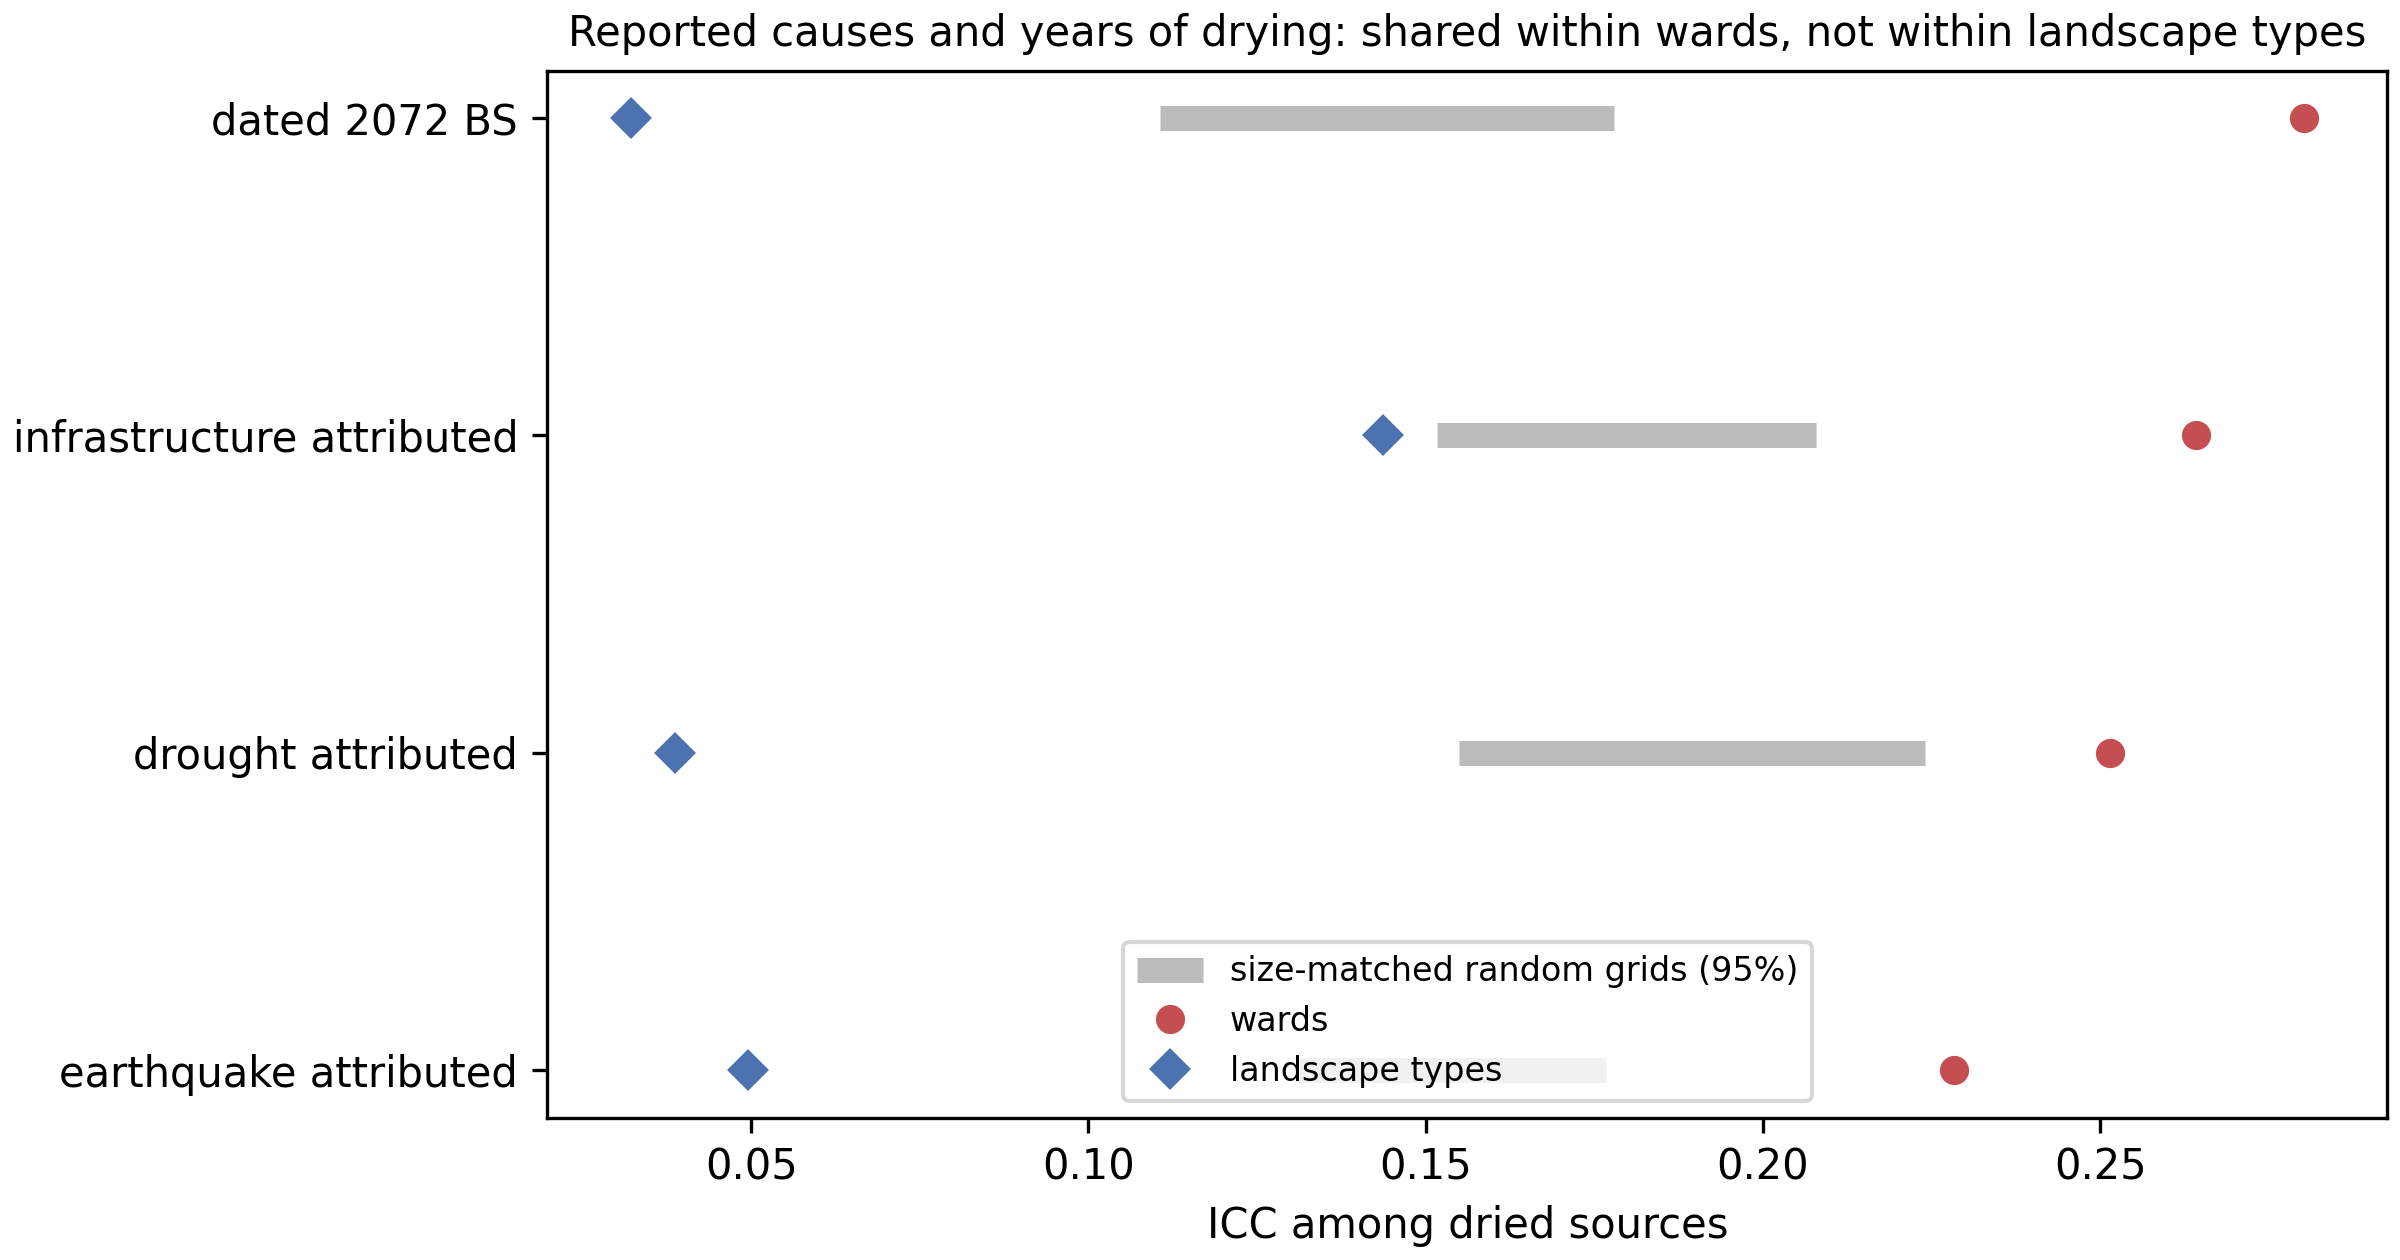

In [5]:
display(table("un_dried_icc.csv")); fig("un_dried_mining.png", 800)

## Apriori narrative rules

In [6]:
n = table("pm_narrative_rules.csv")
n[["consequent", "antecedent", "n", "support", "confidence", "lift", "q_bh", "mh_or_ward", "mh_ci_low", "ward_robust"]].head(40)

,consequent,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,ward_robust
0,reason=earthquake,period=2072 BS,538,0.3537,0.8401,2.4527,0.0000,166.4376,87.2432,True
1,reason=earthquake,landscape type=T5 & period=2072 BS,220,0.1446,0.9000,2.6274,0.0000,24.6869,13.0554,True
2,reason=earthquake,ownership=private & period=2072 BS,182,0.1197,0.9011,2.6307,0.0000,19.5093,9.8783,True
3,reason=earthquake,municipality=Panchkhal & period=2072 BS,168,0.1105,0.8988,2.6240,0.0000,114.2081,46.6073,True
4,reason=earthquake,ownership=community & period=2072 BS,128,0.0842,0.9219,2.6913,0.0000,28.0150,13.2824,True
5,reason=earthquake,municipality=Temal & period=2072 BS,100,0.0657,0.9400,2.7442,0.0000,299.8510,69.7627,True
6,reason=earthquake,landscape type=T5 & source=spring,474,0.3116,0.4346,1.2688,0.0000,1.2090,0.8723,False
7,reason=earthquake,municipality=Panchkhal & source=spring,327,0.2150,0.4679,1.3660,0.0000,3.4109,1.9194,True
8,reason=earthquake,landscape type=T5 & surveyed land use=sparse_forest,249,0.1637,0.4578,1.3366,0.0002,0.9496,0.6630,False
9,reason=earthquake,landscape type=T5 & municipality=Panchkhal,205,0.1348,0.4732,1.3814,0.0002,0.9080,0.5075,False


In [7]:
pd.read_csv(M / "un_type_by_reason.csv", index_col=0).round(3)

,drought,earthquake,infrastructure_development,other
type,,,,
T1,0.197,0.082,0.557,0.164
T2,0.317,0.331,0.065,0.288
T3,0.433,0.232,0.170,0.165
T4,0.302,0.415,0.075,0.208
T5,0.366,0.403,0.097,0.134
T6,0.226,0.372,0.109,0.292
T7,0.254,0.366,0.141,0.239
T8,0.108,0.482,0.277,0.133
